# Proyecto de Computación Científica: modelo Fisher-KPP

**Tema:** propagación espacial de una variable normalizada asociada al capital productivo entre regiones.

**Tipo de estudio:** modelación matemática y simulación computacional con escenarios hipotéticos.

Este cuaderno reproduce los experimentos numéricos del proyecto y genera cada gráfica por separado. Los escenarios son **adimensionales e hipotéticos**: no representan mediciones del capital real de regiones colombianas.

## ¿Qué estudiaremos?

Usaremos la ecuación Fisher-KPP normalizada:

$$
\frac{\partial u}{\partial t}=D\frac{\partial^2u}{\partial x^2}+ru(1-u),
$$

donde $u(x,t)$ es la variable normalizada, $D$ es el coeficiente de difusión espacial y $r$ es la tasa de crecimiento local. Como $u=w/K$, trabajaremos con saturación normalizada igual a uno.

La velocidad mínima teórica de las ondas viajeras es:

$$
c_{\min}=2\sqrt{Dr}.
$$

**Orden recomendado:** ejecutar las celdas de arriba hacia abajo con `Entorno de ejecución > Ejecutar todas` en Google Colab.

**Actualización de validación:** al final se incluyen pruebas independientes de paso temporal y espacial, además de una simulación con horizonte temporal extendido. Estas pruebas complementan los experimentos iniciales y permiten distinguir entre error de discretización y transitorio de propagación.

## 1. Importar bibliotecas

Usaremos NumPy para los arreglos y operaciones numéricas, Matplotlib para las gráficas y Pandas para organizar la tabla de resultados. No es necesario instalar paquetes adicionales en Colab.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Numba acelera los pasos numéricos. Si no está disponible, el cuaderno
# continúa funcionando con NumPy sin esta optimización.
try:
    from numba import njit
    NUMBA_AVAILABLE = True
    print("Aceleración JIT con Numba activada.")
except ImportError:
    NUMBA_AVAILABLE = False
    print("Numba no está disponible; se utilizará NumPy estándar.")

# Carpeta donde guardaremos las gráficas y tablas generadas.
OUT = Path("resultados_fisher_kpp")
OUT.mkdir(exist_ok=True)

print("Bibliotecas cargadas correctamente.")
print("Los resultados se guardarán en:", OUT.resolve())

Aceleración JIT con Numba activada.
Bibliotecas cargadas correctamente.
Los resultados se guardarán en: /content/resultados_fisher_kpp


## 2. Definir el dominio espacial y temporal

Se construye una malla uniforme en el espacio. El dominio es $[-50,250]$, con paso espacial $\Delta x=0.2$. El tiempo final es $T=40$, con paso temporal $\Delta t=0.0005$.

El perfil inicial es una transición suave desde $u\approx 1$ hacia $u\approx 0$. La condición de frontera de Neumann representa flujo nulo en los extremos del dominio.

In [ ]:
# Parámetros numéricos
x_min, x_max = -50.0, 250.0
dx = 0.2
dt = 5e-4
T = 40.0
x0 = 0.0
delta = 0.5

# Malla espacial y cantidad de pasos temporales
x = np.arange(x_min, x_max + dx/2, dx)
t_steps = int(round(T / dt))
t = np.arange(t_steps + 1) * dt

print(f"Número de puntos espaciales: {len(x)}")
print(f"Número de pasos temporales: {t_steps}")
print(f"Tiempo final: {T}")

Número de puntos espaciales: 1501
Número de pasos temporales: 80000
Tiempo final: 40.0


## 3. Condición inicial, posición del frente y ecuación semidiscreta

La condición inicial elegida es:

$$
u(x,0)=\frac{1}{1+\exp((x-x_0)/\delta)}.
$$

El frente se define como la posición donde $u=0.5$. Para estimar esa posición con mayor precisión que la malla, se interpola linealmente entre los dos puntos que rodean el cruce.

La segunda derivada espacial se aproxima mediante diferencias finitas centrales. En los extremos se implementa la condición de Neumann (derivada espacial nula).

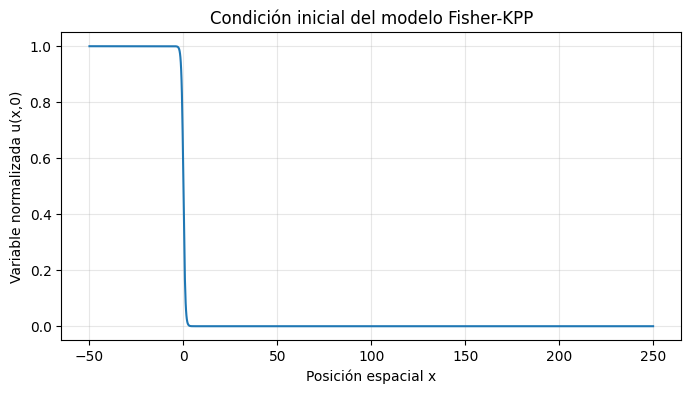

In [ ]:
def initial_profile(x_values):
    """Perfil inicial tipo frente: conecta aproximadamente u=1 con u=0."""
    q = np.clip((x_values - x0) / delta, -60, 60)
    return 1.0 / (1.0 + np.exp(q))


def front_position(u, threshold=0.5):
    """Posición del cruce descendente u=threshold, con interpolación lineal."""
    idx = np.where((u[:-1] >= threshold) & (u[1:] < threshold))[0]
    if len(idx) == 0:
        return np.nan
    i = idx[-1]
    fraction = (threshold - u[i]) / (u[i+1] - u[i])
    return x[i] + fraction * dx


def rhs(u, D, r):
    """Lado derecho de la ecuación tras discretizar el espacio."""
    lap = np.empty_like(u)
    lap[1:-1] = (u[2:] - 2.0*u[1:-1] + u[:-2]) / dx**2

    # Fronteras de Neumann: du/dx = 0 en ambos extremos.
    lap[0] = 2.0 * (u[1] - u[0]) / dx**2
    lap[-1] = 2.0 * (u[-2] - u[-1]) / dx**2

    return D * lap + r * u * (1.0 - u)


# Compilar la función de evaluación si Numba está disponible.
if NUMBA_AVAILABLE:
    rhs = njit(rhs)

u0 = initial_profile(x)
plt.figure(figsize=(8, 4))
plt.plot(x, u0)
plt.xlabel("Posición espacial x")
plt.ylabel("Variable normalizada u(x,0)")
plt.title("Condición inicial del modelo Fisher-KPP")
plt.grid(alpha=0.3)
plt.show()

## 4. Implementar el método Runge-Kutta de cuarto orden (RK4)

RK4 aproxima la solución temporal usando cuatro evaluaciones de la función en cada paso. Se utiliza para resolver el sistema de ecuaciones diferenciales ordinarias que resulta de discretizar el espacio.

In [ ]:
def rk4_step(u, D, r):
    """Realiza un paso temporal de Runge-Kutta de cuarto orden."""
    k1 = rhs(u, D, r)
    k2 = rhs(u + 0.5*dt*k1, D, r)
    k3 = rhs(u + 0.5*dt*k2, D, r)
    k4 = rhs(u + dt*k3, D, r)
    return u + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)


# La compilación JIT reduce el tiempo de ejecución de las simulaciones.
if NUMBA_AVAILABLE:
    rk4_step = njit(rk4_step)


def simulate_rk4(D, r, save_every=100):
    """Simula Fisher-KPP con RK4 y guarda perfiles y posiciones del frente."""
    u = initial_profile(x)
    saved_t = [0.0]
    saved_u = [u.copy()]
    fronts_t = [0.0]
    fronts_x = [front_position(u)]

    for n in range(1, t_steps + 1):
        u = rk4_step(u, D, r)
        if n % save_every == 0 or n == t_steps:
            tn = n * dt
            saved_t.append(tn)
            saved_u.append(u.copy())
            fronts_t.append(tn)
            fronts_x.append(front_position(u))

    return (np.array(saved_t), np.array(saved_u),
            np.array(fronts_t), np.array(fronts_x))

print("Funciones RK4 definidas.")

Funciones RK4 definidas.


## 5. Estimar la velocidad del frente

La posición del frente se registra en distintos instantes. Luego se ajusta una recta:

$$
x_f(t)\approx a+ct,
$$

donde la pendiente $c$ es la velocidad numérica estimada. El ajuste se realiza entre $t=15$ y $t=40$, para reducir la influencia del transitorio inicial.

También calculamos $R^2$, que indica qué tan bien la recta describe la relación entre posición y tiempo.

In [ ]:
def fit_speed(times, positions, t_start=15.0, t_end=40.0):
    mask = ((times >= t_start) & (times <= t_end)
            & np.isfinite(positions))
    if np.count_nonzero(mask) < 2:
        raise ValueError("No hay suficientes posiciones válidas para ajustar la velocidad.")

    slope, intercept = np.polyfit(times[mask], positions[mask], 1)
    pred = slope*times[mask] + intercept
    ss_res = np.sum((positions[mask] - pred)**2)
    ss_tot = np.sum((positions[mask] - np.mean(positions[mask]))**2)
    r2 = 1.0 - ss_res/ss_tot if ss_tot > 0 else np.nan
    return slope, intercept, r2


def theoretical_speed(D, r):
    return 2.0 * np.sqrt(D*r)

print("Funciones de estimación de velocidad definidas.")

Funciones de estimación de velocidad definidas.


## 6. Experimento 1: variar el coeficiente de difusión D

En este experimento mantenemos $r=1$ y variamos $D$ entre 0.5, 1 y 2. Así aislamos el efecto del coeficiente de difusión sobre la propagación espacial.

La predicción teórica es que $c_{\min}=2\sqrt{Dr}$ aumenta cuando aumenta $D$.

In [ ]:
cases_D = [0.5, 1.0, 2.0]
profiles_D = {}
rows_D = []

for D in cases_D:
    r = 1.0
    st, su, ft, fx = simulate_rk4(D, r)
    c_num, intercept, r2 = fit_speed(ft, fx)
    c_teo = theoretical_speed(D, r)
    error = abs(c_num - c_teo) / c_teo * 100

    profiles_D[D] = (st, su, ft, fx)
    rows_D.append({
        "Experimento": "Variación de D",
        "D": D,
        "r": r,
        "Velocidad teórica": c_teo,
        "Velocidad numérica": c_num,
        "Error relativo (%)": error,
        "R2": r2
    })

results_D = pd.DataFrame(rows_D)
results_D

,Experimento,D,r,Velocidad teórica,Velocidad numérica,Error relativo (%),R2
0,Variación de D,0.5,1.0,1.414214,1.381811,2.291203,0.999988
1,Variación de D,1.0,1.0,2.000000,1.946060,2.697008,0.999984
2,Variación de D,2.0,1.0,2.828427,2.748143,2.838465,0.999982


### Gráfica 1. Perfiles espaciales para diferentes valores de D

La gráfica muestra el perfil de la variable normalizada en el tiempo final. Al comparar la posición del frente para cada valor de D, se observa cómo cambia la extensión espacial de la propagación.

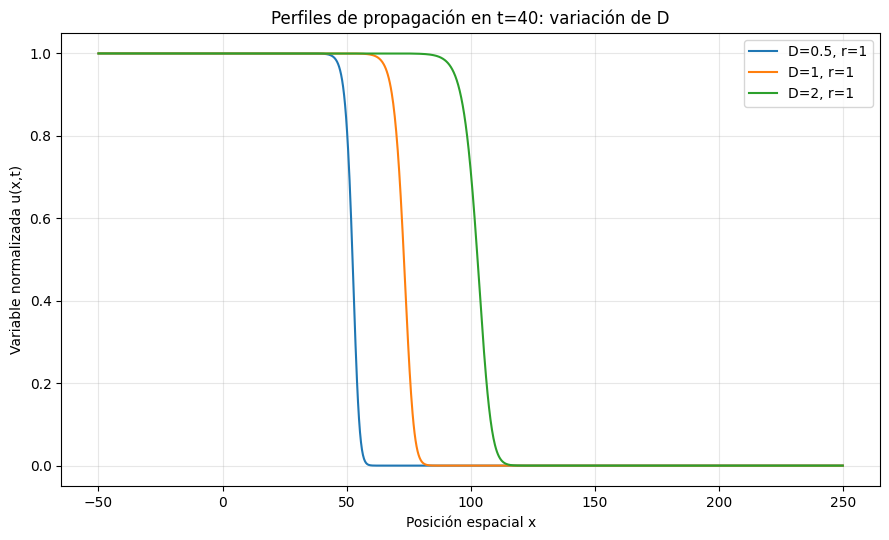

In [ ]:
plt.figure(figsize=(9, 5.5))
for D in cases_D:
    st, su, _, _ = profiles_D[D]
    idx = np.argmin(np.abs(st - T))
    plt.plot(x, su[idx], label=f"D={D:g}, r=1")

plt.xlabel("Posición espacial x")
plt.ylabel("Variable normalizada u(x,t)")
plt.title(f"Perfiles de propagación en t={T:g}: variación de D")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "perfiles_variacion_D.png", dpi=180)
plt.show()

### Gráfica 2. Posición del frente al variar D

Se representa la posición del cruce u=0.5 a lo largo del tiempo. Una pendiente mayor indica una velocidad de propagación más alta.

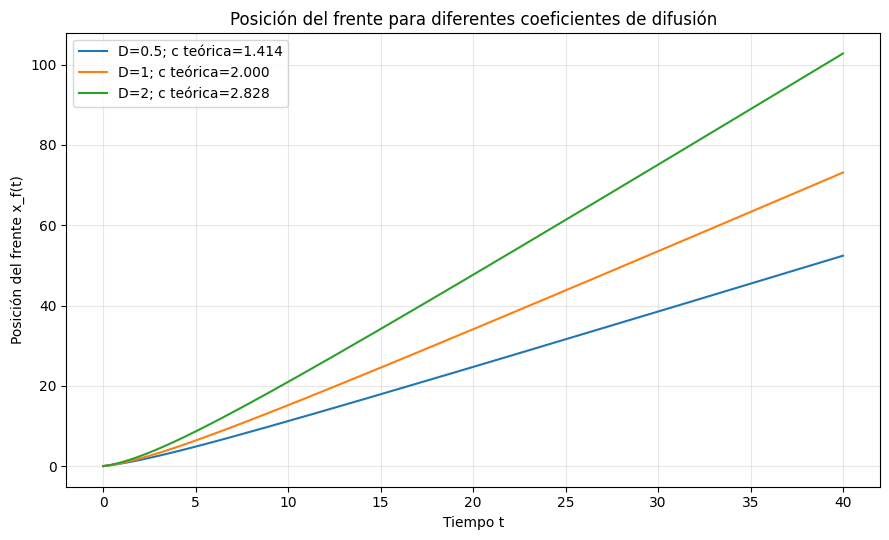

In [ ]:
plt.figure(figsize=(9, 5.5))
for D in cases_D:
    _, _, ft, fx = profiles_D[D]
    plt.plot(ft, fx, label=f"D={D:g}; c teórica={theoretical_speed(D, 1):.3f}")

plt.xlabel("Tiempo t")
plt.ylabel("Posición del frente x_f(t)")
plt.title("Posición del frente para diferentes coeficientes de difusión")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "posicion_frente_D.png", dpi=180)
plt.show()

## 7. Experimento 2: variar la tasa de crecimiento r

Ahora mantenemos $D=1$ y variamos $r$ entre 0.5, 1 y 2. Este experimento permite analizar la influencia del crecimiento local sobre la propagación del frente.

In [ ]:
cases_r = [0.5, 1.0, 2.0]
profiles_r = {}
rows_r = []

for r in cases_r:
    D = 1.0
    st, su, ft, fx = simulate_rk4(D, r)
    c_num, intercept, r2 = fit_speed(ft, fx)
    c_teo = theoretical_speed(D, r)
    error = abs(c_num - c_teo) / c_teo * 100

    profiles_r[r] = (st, su, ft, fx)
    rows_r.append({
        "Experimento": "Variación de r",
        "D": D,
        "r": r,
        "Velocidad teórica": c_teo,
        "Velocidad numérica": c_num,
        "Error relativo (%)": error,
        "R2": r2
    })

results_r = pd.DataFrame(rows_r)
results_r

,Experimento,D,r,Velocidad teórica,Velocidad numérica,Error relativo (%),R2
0,Variación de r,1.0,0.5,1.414214,1.324277,6.359449,0.999899
1,Variación de r,1.0,1.0,2.000000,1.946060,2.697008,0.999984
2,Variación de r,1.0,2.0,2.828427,2.847930,0.689535,0.989729


### Gráfica 3. Perfiles espaciales para diferentes valores de r

Se comparan los perfiles al tiempo final. Un crecimiento local mayor puede acelerar el avance del frente, lo cual también se refleja en la expresión teórica de la velocidad mínima.

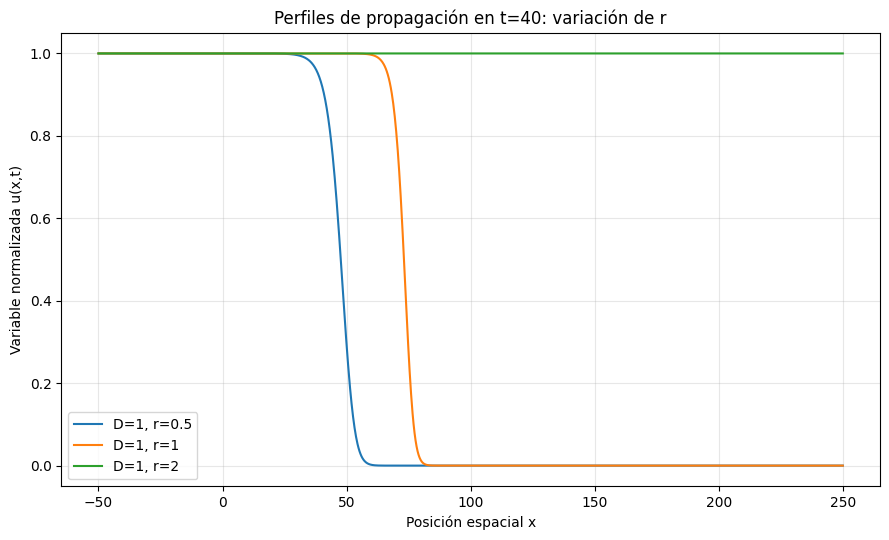

In [ ]:
plt.figure(figsize=(9, 5.5))
for r in cases_r:
    st, su, _, _ = profiles_r[r]
    idx = np.argmin(np.abs(st - T))
    plt.plot(x, su[idx], label=f"D=1, r={r:g}")

plt.xlabel("Posición espacial x")
plt.ylabel("Variable normalizada u(x,t)")
plt.title(f"Perfiles de propagación en t={T:g}: variación de r")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "perfiles_variacion_r.png", dpi=180)
plt.show()

## 8. Experimento 3: comparar RK4 y Adams-Bashforth de cuarto orden

Adams-Bashforth de cuarto orden (AB4) es un método explícito multipaso. Necesita valores de varios instantes anteriores; por eso se utilizan tres pasos iniciales de RK4 para iniciar el método.

La comparación se realiza para el escenario base $D=1$, $r=1$.

In [ ]:
def simulate_ab4(D, r, save_every=100):
    """Simula con Adams-Bashforth 4; RK4 genera los tres pasos iniciales."""
    u = initial_profile(x)
    f_hist = []

    # Generar los tres primeros pasos con RK4.
    for _ in range(3):
        f_hist.insert(0, rhs(u, D, r))
        u = rk4_step(u, D, r)

    # En este punto u corresponde al instante 3*dt.
    f_hist.insert(0, rhs(u, D, r))

    fronts_t = [0.0]
    fronts_x = [front_position(initial_profile(x))]
    saved_t = [0.0]
    saved_u = [initial_profile(x)]

    for n in range(4, t_steps + 1):
        u = u + (dt/24.0) * (
            55*f_hist[0] - 59*f_hist[1]
            + 37*f_hist[2] - 9*f_hist[3]
        )
        f_new = rhs(u, D, r)
        f_hist = [f_new] + f_hist[:3]

        if n % save_every == 0 or n == t_steps:
            tn = n * dt
            saved_t.append(tn)
            saved_u.append(u.copy())
            fronts_t.append(tn)
            fronts_x.append(front_position(u))

    return (np.array(saved_t), np.array(saved_u),
            np.array(fronts_t), np.array(fronts_x))

# Escenario base
D_base, r_base = 1.0, 1.0
rk_t, rk_u, rk_ft, rk_fx = profiles_D[1.0]
ab_t, ab_u, ab_ft, ab_fx = simulate_ab4(D_base, r_base)

rk_speed, _, rk_r2 = fit_speed(rk_ft, rk_fx)
ab_speed, _, ab_r2 = fit_speed(ab_ft, ab_fx)

print(f"Velocidad estimada RK4: {rk_speed:.8f}")
print(f"Velocidad estimada AB4: {ab_speed:.8f}")
print(f"Diferencia absoluta: {abs(rk_speed-ab_speed):.3e}")

Velocidad estimada RK4: 1.94605983
Velocidad estimada AB4: 1.94605983
Diferencia absoluta: 5.258e-13


### Gráfica 4. Comparación de la posición del frente con RK4 y AB4

Si las curvas se superponen, significa que ambos métodos producen estimaciones muy cercanas para este escenario y esta resolución. Esto no demuestra por sí solo que ambos sean igualmente precisos: también se debe estudiar el refinamiento de malla y el error frente a una referencia.

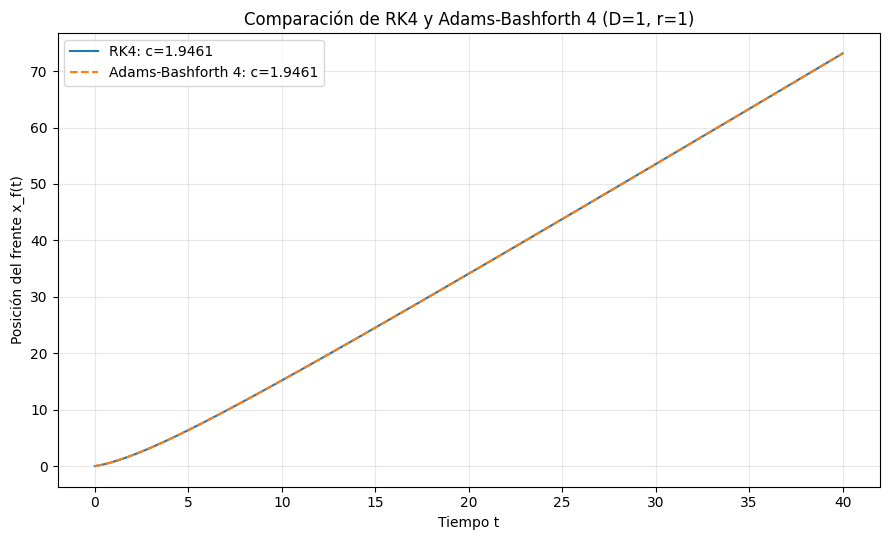

In [ ]:
plt.figure(figsize=(9, 5.5))
plt.plot(rk_ft, rk_fx, label=f"RK4: c={rk_speed:.4f}")
plt.plot(ab_ft, ab_fx, "--", label=f"Adams-Bashforth 4: c={ab_speed:.4f}")
plt.xlabel("Tiempo t")
plt.ylabel("Posición del frente x_f(t)")
plt.title("Comparación de RK4 y Adams-Bashforth 4 (D=1, r=1)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "comparacion_RK4_AB4.png", dpi=180)
plt.show()

## 9. Análisis del espacio fase y órbita heteroclínica

Con la transformación viajera $z=x-ct$, y definiendo $V=U'$, se obtiene el sistema:

$$
U'=V,\qquad V'=-\frac{c}{D}V-\frac{r}{D}U(1-U).
$$

Los equilibrios son $(U,V)=(0,0)$ y $(1,0)$ en la variable normalizada. Una onda viajera monotónica corresponde a una trayectoria que conecta ambos equilibrios. Para $D=r=1$, se ilustra el caso de velocidad mínima $c=2$.

In [ ]:
def phase_rhs(y, D, r, c):
    U, V = y
    return np.array([
        V,
        -(c/D)*V - (r/D)*U*(1.0-U)
    ])


def phase_trajectory(D=1.0, r=1.0, c=None, h=0.001, zmax=100.0):
    if c is None:
        c = 2*np.sqrt(D*r)

    # Inicio muy cercano al equilibrio U=1, siguiendo la dirección adecuada.
    eps = 1e-5
    lam = -c/(2.0*D) + np.sqrt((c/(2.0*D))**2 + r/D)
    y = np.array([1.0-eps, -lam*eps])

    zs = np.arange(0.0, zmax+h, h)
    traj = np.empty((len(zs), 2))
    traj[0] = y

    for i in range(1, len(zs)):
        k1 = phase_rhs(y, D, r, c)
        k2 = phase_rhs(y+0.5*h*k1, D, r, c)
        k3 = phase_rhs(y+0.5*h*k2, D, r, c)
        k4 = phase_rhs(y+h*k3, D, r, c)
        y = y+(h/6.0)*(k1+2*k2+2*k3+k4)
        traj[i] = y

        if y[0] < -0.02 or abs(y[1]) > 10:
            traj = traj[:i+1]
            break

    return traj

traj = phase_trajectory(D=1.0, r=1.0, c=2.0)
print("Punto inicial aproximado:", traj[0])
print("Punto final aproximado:", traj[-1])

Punto inicial aproximado: [ 9.99990000e-01 -4.14213562e-06]
Punto final aproximado: [ 6.78647838e-30 -6.68876205e-30]


### Gráfica 5. Trayectoria en el espacio fase

El eje horizontal representa U y el vertical representa V=U'. Los extremos de la trayectoria se aproximan a los puntos de equilibrio (1,0) y (0,0). Esta conexión es la órbita heteroclínica asociada al perfil de onda viajera.

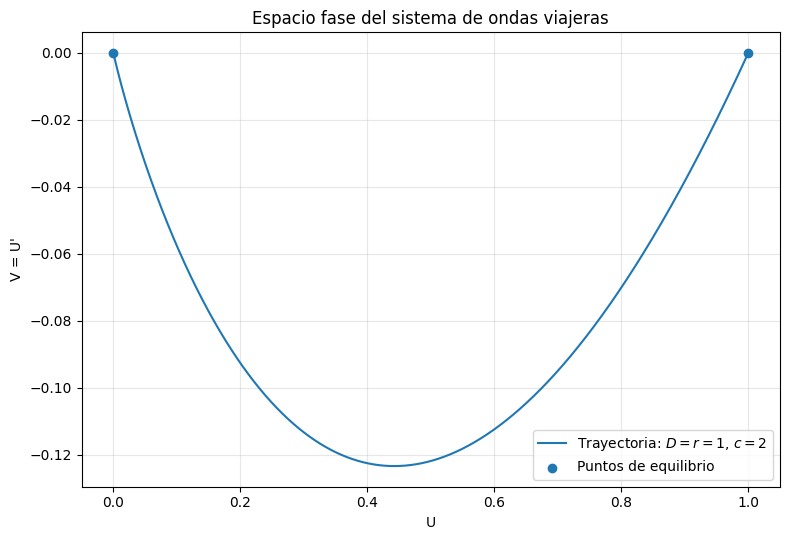

In [ ]:
plt.figure(figsize=(8, 5.5))
plt.plot(traj[:, 0], traj[:, 1],
         label=r"Trayectoria: $D=r=1$, $c=2$")
plt.scatter([0, 1], [0, 0], zorder=3,
            label="Puntos de equilibrio")
plt.xlabel("U")
plt.ylabel("V = U'")
plt.title("Espacio fase del sistema de ondas viajeras")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "espacio_fase.png", dpi=180)
plt.show()

## 10. Consolidar resultados en una tabla

Unimos los resultados de los experimentos de difusión y crecimiento. El error relativo porcentual se calcula comparando la velocidad numérica estimada con la velocidad mínima teórica.

In [ ]:
results = pd.concat([results_D, results_r], ignore_index=True)

# Agregar el escenario base de la comparación de métodos como información adicional.
results = results.sort_values(["Experimento", "D", "r"]).reset_index(drop=True)

pd.set_option("display.precision", 6)
display(results)

results.to_csv(OUT / "resultados_velocidad.csv", index=False)
print("Tabla guardada en:", (OUT / "resultados_velocidad.csv").resolve())

,Experimento,D,r,Velocidad teórica,Velocidad numérica,Error relativo (%),R2
0,Variación de D,0.5,1.0,1.414214,1.381811,2.291203,0.999988
1,Variación de D,1.0,1.0,2.000000,1.946060,2.697008,0.999984
2,Variación de D,2.0,1.0,2.828427,2.748143,2.838465,0.999982
3,Variación de r,1.0,0.5,1.414214,1.324277,6.359449,0.999899
4,Variación de r,1.0,1.0,2.000000,1.946060,2.697008,0.999984
5,Variación de r,1.0,2.0,2.828427,2.847930,0.689535,0.989729


Tabla guardada en: /content/resultados_fisher_kpp/resultados_velocidad.csv


## 11. Revisar los resultados y su interpretación

### ¿Qué debemos observar?

1. **Al aumentar D**, la velocidad mínima teórica \(2\sqrt{Dr}\) aumenta. La difusión más intensa favorece una propagación espacial más rápida.
2. **Al aumentar r**, también aumenta la velocidad mínima teórica. El crecimiento local más rápido acelera el avance del frente.
3. **RK4 y AB4** deben compararse con los mismos parámetros y pasos. Una coincidencia entre curvas es evidencia de consistencia entre esas ejecuciones, pero no reemplaza un estudio de convergencia.
4. **La órbita heteroclínica** conecta los equilibrios \((1,0)\) y \((0,0)\) en el espacio fase para la onda considerada.


## 12. Validación adicional: separar los efectos de la malla espacial y temporal

En la prueba inicial se modificaron simultáneamente $\Delta x$ y $\Delta t$. Esa comparación es útil como refinamiento conjunto, pero no permite identificar qué parte del cambio se debe a cada paso. Por eso se realizan dos pruebas adicionales:

1. **Refinamiento temporal:** se mantiene $\Delta x=0.2$ y se comparan tres valores de $\Delta t$.
2. **Refinamiento espacial:** se mantiene $\Delta t=0.00025$ y se comparan tres valores de $\Delta x$.

En ambas pruebas se conservan $D=r=1$, el dominio $[-50,250]$, $T=40$, el perfil inicial y la ventana de ajuste $15\leq t\leq40$. Se utiliza la misma condición de frontera de flujo nulo.

Para estas pruebas, la condición inicial se evalúa con una expresión logística numéricamente estable. Esto evita introducir un pequeño valor positivo artificial en toda la cola derecha al truncar el exponente, algo importante cuando se extiende el tiempo de simulación.

### Código de validación independiente

La siguiente celda ejecuta ambas pruebas, guarda sus tablas CSV y genera una figura comparativa. La velocidad se ajusta en la ventana temporal $15\leq t\leq40$, igual que en los experimentos principales.

REFINAMIENTO TEMPORAL (dx fijo = 0.2)


,dx,dt,c_numerica,error_vs_cmin_pct,R2,u_min,u_max
0,0.2,0.00100,1.94606,2.697008,0.999984,8.792974e-130,1.0
1,0.2,0.00050,1.94606,2.697008,0.999984,8.792974e-130,1.0
2,0.2,0.00025,1.94606,2.697008,0.999984,8.792974e-130,1.0


REFINAMIENTO ESPACIAL (dt fijo = 0.00025)


,dx,dt,c_numerica,error_vs_cmin_pct,R2,u_min,u_max
0,0.4,0.00025,1.954886,2.255695,0.999983,6.289787e-127,1.0
1,0.2,0.00025,1.946060,2.697008,0.999984,8.792974e-130,1.0
2,0.1,0.00025,1.943809,2.809542,0.999984,1.756379e-130,1.0


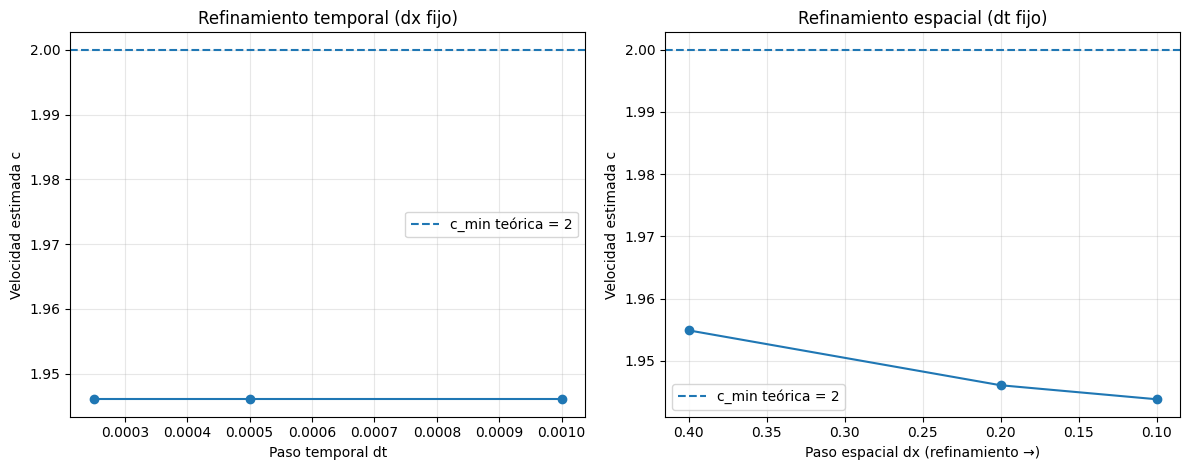

Rango de u en refinamiento temporal: 8.792973578838824e-130 a 1.0
Rango de u en refinamiento espacial: 1.7563788577768773e-130 a 1.0


In [ ]:
# Validación adicional reproducible: funciones independientes de dx y dt.
# Se usa Numba si está disponible; de lo contrario, el código sigue funcionando.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

try:
    from numba import njit
    JIT_OK = True
except ImportError:
    JIT_OK = False
    def njit(func):
        return func

OUT_VALIDACION = Path("resultados_fisher_kpp")
OUT_VALIDACION.mkdir(exist_ok=True)

@njit
def rhs_validacion(u, D, r, dx):
    n = u.size
    f = np.empty_like(u)
    # Neumann: derivada espacial nula en ambos extremos.
    f[0] = 2.0*D*(u[1]-u[0])/(dx*dx) + r*u[0]*(1.0-u[0])
    for i in range(1, n-1):
        f[i] = D*(u[i+1]-2.0*u[i]+u[i-1])/(dx*dx) + r*u[i]*(1.0-u[i])
    f[n-1] = 2.0*D*(u[n-2]-u[n-1])/(dx*dx) + r*u[n-1]*(1.0-u[n-1])
    return f

@njit
def rk4_validacion(u, D, r, dx, dt):
    k1 = rhs_validacion(u, D, r, dx)
    k2 = rhs_validacion(u + 0.5*dt*k1, D, r, dx)
    k3 = rhs_validacion(u + 0.5*dt*k2, D, r, dx)
    k4 = rhs_validacion(u + dt*k3, D, r, dx)
    return u + (dt/6.0)*(k1+2.0*k2+2.0*k3+k4)

def perfil_estable(x_values, x0=0.0, delta=0.5):
    # exp(-logaddexp(0,q)) evalúa 1/(1+exp(q)) sin crear una cola
    # artificialmente positiva por truncamiento del exponente.
    q = (np.asarray(x_values)-x0)/delta
    return np.exp(-np.logaddexp(0.0, q))

def posicion_frente(x_values, u_values, umbral=0.5):
    ids = np.where((u_values[:-1] >= umbral) & (u_values[1:] < umbral))[0]
    if len(ids) == 0:
        return np.nan
    i = ids[-1]
    return x_values[i] + (umbral-u_values[i])/(u_values[i+1]-u_values[i])*(x_values[i+1]-x_values[i])

def simular_validacion(dx, dt, T=40.0, D=1.0, r=1.0,
                       xmin=-50.0, xmax=250.0, guardar_cada=0.05):
    xloc = np.arange(xmin, xmax+dx/2.0, dx)
    u = perfil_estable(xloc)
    nsteps = int(round(T/dt))
    stride = max(1, int(round(guardar_cada/dt)))
    tiempos = [0.0]
    frentes = [posicion_frente(xloc, u)]
    umin, umax = float(u.min()), float(u.max())
    for n in range(1, nsteps+1):
        u = rk4_validacion(u, D, r, dx, dt)
        if n % stride == 0 or n == nsteps:
            tiempos.append(n*dt)
            frentes.append(posicion_frente(xloc, u))
    tiempos = np.asarray(tiempos)
    frentes = np.asarray(frentes)
    umin, umax = float(u.min()), float(u.max())
    mask = (tiempos >= 15.0) & (tiempos <= T) & np.isfinite(frentes)
    if mask.sum() < 3:
        raise ValueError("No hay suficientes posiciones de frente para ajustar la velocidad.")
    c, intercepto = np.polyfit(tiempos[mask], frentes[mask], 1)
    pred = c*tiempos[mask] + intercepto
    ss_res = np.sum((frentes[mask]-pred)**2)
    ss_tot = np.sum((frentes[mask]-frentes[mask].mean())**2)
    r2 = 1.0-ss_res/ss_tot if ss_tot > 0 else np.nan
    return c, r2, umin, umax, tiempos, frentes

# A. Refinamiento temporal: dx fijo.
filas_dt = []
for dt_test in [0.001, 0.0005, 0.00025]:
    c, r2, umin, umax, _, _ = simular_validacion(dx=0.2, dt=dt_test)
    filas_dt.append({"dx":0.2, "dt":dt_test, "c_numerica":c,
                     "error_vs_cmin_pct":abs(c-2.0)/2.0*100,
                     "R2":r2, "u_min":umin, "u_max":umax})

df_dt = pd.DataFrame(filas_dt)
df_dt.to_csv(OUT_VALIDACION/"convergencia_temporal_independiente.csv", index=False)
print("REFINAMIENTO TEMPORAL (dx fijo = 0.2)")
display(df_dt)

# B. Refinamiento espacial: dt fijo.
filas_dx = []
for dx_test in [0.4, 0.2, 0.1]:
    c, r2, umin, umax, _, _ = simular_validacion(dx=dx_test, dt=0.00025)
    filas_dx.append({"dx":dx_test, "dt":0.00025, "c_numerica":c,
                     "error_vs_cmin_pct":abs(c-2.0)/2.0*100,
                     "R2":r2, "u_min":umin, "u_max":umax})

df_dx = pd.DataFrame(filas_dx)
df_dx.to_csv(OUT_VALIDACION/"convergencia_espacial_independiente.csv", index=False)
print("REFINAMIENTO ESPACIAL (dt fijo = 0.00025)")
display(df_dx)

# Gráfica comparativa de las pruebas independientes.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(df_dt["dt"], df_dt["c_numerica"], "o-")
axes[0].axhline(2.0, linestyle="--", label="c_min teórica = 2")
axes[0].set_xlabel("Paso temporal dt")
axes[0].set_ylabel("Velocidad estimada c")
axes[0].set_title("Refinamiento temporal (dx fijo)")
axes[0].grid(alpha=0.3); axes[0].legend()
axes[1].plot(df_dx["dx"], df_dx["c_numerica"], "o-")
axes[1].axhline(2.0, linestyle="--", label="c_min teórica = 2")
axes[1].invert_xaxis()
axes[1].set_xlabel("Paso espacial dx (refinamiento →)")
axes[1].set_ylabel("Velocidad estimada c")
axes[1].set_title("Refinamiento espacial (dt fijo)")
axes[1].grid(alpha=0.3); axes[1].legend()
plt.tight_layout()
plt.savefig(OUT_VALIDACION/"refinamientos_independientes.png", dpi=180)
plt.show()

print("Rango de u en refinamiento temporal:",
      float(df_dt.u_min.min()), "a", float(df_dt.u_max.max()))
print("Rango de u en refinamiento espacial:",
      float(df_dx.u_min.min()), "a", float(df_dx.u_max.max()))

## 13. Simulación con horizonte temporal extendido

La velocidad mínima teórica $c_{\min}=2$ es una propiedad asintótica del modelo Fisher--KPP para condiciones iniciales suficientemente localizadas. Por ello, una simulación hasta $T=40$ puede medir todavía un régimen transitorio. Para examinar este efecto se amplía el dominio espacial hasta $[-50,500]$ y se simula hasta $T=120$, conservando $D=r=1$, $\Delta x=0.2$ y $\Delta t=0.0005$.

La velocidad se estima en ventanas sucesivas. Se utiliza una evaluación estable del perfil inicial, de modo que la cola derecha no contenga pequeñas semillas numéricas artificiales que, a tiempos largos, podrían crecer y alterar la propagación.

### Código para horizonte temporal extendido

La celda calcula velocidades en ventanas temporales y guarda los resultados. La comparación permite evaluar si el valor medido se aproxima gradualmente a la velocidad mínima teórica.

,T_simulado,ventana,c_estimado,error_vs_2_pct,R2,u_min_final,u_max_final
0,40.0,15-40,1.946060,2.697008,0.999984,0.000000e+00,1.0
1,80.0,15-40,1.946060,2.697008,0.999984,3.865819e-259,1.0
2,80.0,40-80,1.978946,1.052721,0.999999,3.865819e-259,1.0
3,120.0,15-40,1.946060,2.697008,0.999984,1.586614e-171,1.0
4,120.0,40-80,1.978946,1.052721,0.999999,1.586614e-171,1.0
5,120.0,80-120,1.989083,0.545840,1.000000,1.586614e-171,1.0


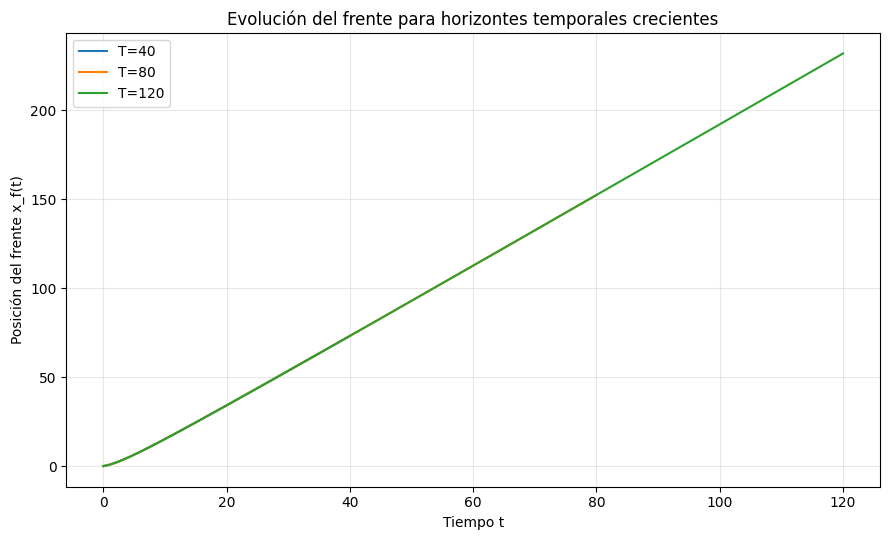

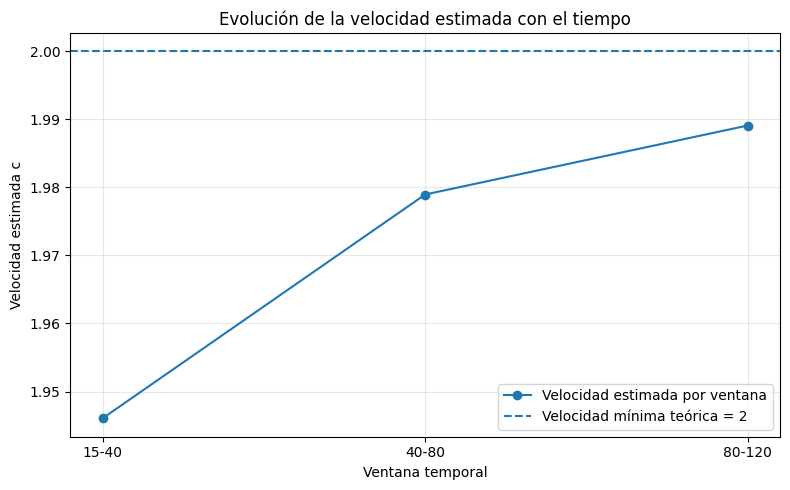

In [ ]:
# Simulación extendida: T=40, 80 y 120.
# Se reutilizan rhs_validacion, rk4_validacion, perfil_estable y posicion_frente.
def simular_horizonte_largo(T, dx=0.2, dt=0.0005, D=1.0, r=1.0,
                            xmin=-50.0, xmax=500.0, guardar_cada=0.05):
    xloc = np.arange(xmin, xmax+dx/2.0, dx)
    u = perfil_estable(xloc)
    nsteps = int(round(T/dt))
    stride = max(1, int(round(guardar_cada/dt)))
    tiempos=[0.0]; frentes=[posicion_frente(xloc,u)]
    for n in range(1,nsteps+1):
        u = rk4_validacion(u,D,r,dx,dt)
        if n % stride == 0 or n == nsteps:
            tiempos.append(n*dt)
            frentes.append(posicion_frente(xloc,u))
    return xloc, np.asarray(tiempos), np.asarray(frentes), float(u.min()), float(u.max())

curvas_largas=[]
filas_ventanas=[]
for T_largo in [40.0, 80.0, 120.0]:
    xloc, tt, ff, umin, umax = simular_horizonte_largo(T_largo)
    curvas_largas.append((T_largo,tt,ff))
    ventanas=[(15.0,min(40.0,T_largo)),
              (40.0,min(80.0,T_largo)),
              (80.0,min(120.0,T_largo)),
              (120.0,T_largo)]
    for a,b in ventanas:
        if b-a <= 0: continue
        m=(tt>=a)&(tt<=b)&np.isfinite(ff)
        if m.sum()<3: continue
        c,inter=np.polyfit(tt[m],ff[m],1)
        pred=c*tt[m]+inter
        ssres=np.sum((ff[m]-pred)**2)
        sstot=np.sum((ff[m]-ff[m].mean())**2)
        r2=1-ssres/sstot if sstot>0 else np.nan
        filas_ventanas.append({"T_simulado":T_largo,"ventana":f"{a:g}-{b:g}",
                               "c_estimado":c,"error_vs_2_pct":abs(c-2.0)/2.0*100,
                               "R2":r2,"u_min_final":umin,"u_max_final":umax})

df_largo=pd.DataFrame(filas_ventanas)
df_largo.to_csv(OUT_VALIDACION/"velocidad_ventanas_temporales.csv",index=False)
display(df_largo)

plt.figure(figsize=(9,5.5))
for T_largo,tt,ff in curvas_largas:
    plt.plot(tt,ff,label=f"T={T_largo:g}")
plt.xlabel("Tiempo t")
plt.ylabel("Posición del frente x_f(t)")
plt.title("Evolución del frente para horizontes temporales crecientes")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
plt.savefig(OUT_VALIDACION/"frente_tiempos_largos.png",dpi=180)
plt.show()

plt.figure(figsize=(8,5))
sub=df_largo[df_largo["T_simulado"]==120.0]
plt.plot(range(len(sub)),sub["c_estimado"],"o-",label="Velocidad estimada por ventana")
plt.axhline(2.0,linestyle="--",label="Velocidad mínima teórica = 2")
plt.xticks(range(len(sub)),sub["ventana"])
plt.xlabel("Ventana temporal")
plt.ylabel("Velocidad estimada c")
plt.title("Evolución de la velocidad estimada con el tiempo")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
plt.savefig(OUT_VALIDACION/"velocidad_por_ventana.png",dpi=180)
plt.show()

## 14. Interpretación de la validación y conclusiones computacionales

Los resultados de las pruebas independientes deben leerse de manera diferenciada:

- En el **refinamiento temporal** se mantiene fija la malla espacial. En las ejecuciones de referencia, las velocidades obtenidas para $\Delta t=0.001$, $0.0005$ y $0.00025$ coinciden a seis decimales ($c\approx1.946060$). Esto indica que, para esta configuración y ventana de ajuste, la estimación es poco sensible a esos tres pasos temporales.
- En el **refinamiento espacial** se mantiene fijo $\Delta t=0.00025$. Las velocidades obtenidas para $\Delta x=0.4$, $0.2$ y $0.1$ son aproximadamente $1.954886$, $1.946060$ y $1.943809$. La variación no se acerca monótonamente a 2 en la ventana $15\leq t\leq40$; por tanto, no debe afirmarse convergencia a la velocidad mínima a partir de esta prueba aislada.
- En la **simulación extendida**, para $D=r=1$, las velocidades estimadas en las ventanas $15$--$40$, $40$--$80$ y $80$--$120$ son aproximadamente $1.946060$, $1.978946$ y $1.989083$. La última estimación se acerca más a $c_{\min}=2$, lo que es compatible con la interpretación de la velocidad mínima como comportamiento asintótico.

En las pruebas ejecutadas, la variable se mantuvo dentro del intervalo numérico $[0,1]$. El valor de $R^2$ mide la linealidad del ajuste de la posición del frente, pero no sustituye el análisis de error, estabilidad ni convergencia.